# Visualisierung: PCA und K-Means

Normalisiert alle Metriken eines Jahres, reduziert sie mit einer PCA auf zwei Hauptkomponenten und gruppiert die Länder mit K-Means in drei Cluster.

In [1]:
import pandas as pd
import numpy as np

In [2]:
from bina_db import connect

maria_db_connection = connect()

In [4]:
sql_query_countries = "select id, name from country"
countries = pd.read_sql(sql_query_countries, maria_db_connection)

sql_query_metric_definitions = "select id, name from metric_definition"
metric_definitions = pd.read_sql(sql_query_metric_definitions, maria_db_connection)

In [36]:
# sql_query = "select country, metric_definition, metric.value from metric where year = 2015 and country in (1, 3, 4, 7, 11, 12, 14, 15, 16, 18, 19, 21, 22, 24, 26, 27, 29, 30, 32, 35, 36, 37, 39, 40, 41, 43, 44, 45, 46, 49, 50, 51, 54, 56, 59, 60, 61, 62, 64, 65, 66, 67, 70, 72, 76, 77, 81, 83, 84, 85, 87, 92, 94, 97, 100, 101, 102, 103, 104, 105, 106, 107, 108, 110, 111, 112, 113, 115, 116, 117, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 131, 133, 134, 135, 137, 138, 141, 142, 144, 146, 148, 149, 151, 152, 153, 156, 157, 159, 160, 161, 162, 165, 167, 168, 169, 171, 172, 174, 175, 176, 178, 179, 181, 183, 184, 185, 196, 197, 198, 200, 201, 203, 204, 206, 207, 210, 211, 212, 213, 215, 216, 217, 218, 219, 220, 221, 223, 226, 227, 228, 229, 232, 233, 234, 235, 236, 238, 239, 241, 242, 247, 248, 249, 250)"
sql_query = "select country, metric_definition, metric.value from metric where year = 2017 and country in (1, 3, 4, 7, 11, 12, 14, 15, 16, 18, 19, 21, 22, 24, 26, 27, 29, 30, 32, 35, 36, 37, 39, 40, 41, 43, 44, 45, 46, 49, 50, 51, 54, 56, 59, 60, 61, 62, 64, 65, 66, 67, 70, 72, 76, 77, 81, 83, 84, 85, 87, 92, 94, 97, 100, 101, 102, 103, 104, 105, 106, 107, 108, 110, 111, 112, 113, 115, 116, 117, 120, 121, 122, 123, 124, 125, 126, 127, 128, 130, 131, 133, 134, 135, 137, 138, 141, 142, 144, 146, 148, 149, 151, 152, 153, 156, 157, 159, 160, 161, 162, 165, 167, 168, 169, 171, 172, 174, 175, 176, 178, 179, 181, 183, 184, 185, 196, 197, 198, 200, 201, 203, 204, 206, 207, 210, 211, 212, 213, 215, 216, 217, 218, 219, 220, 221, 223, 226, 227, 228, 229, 232, 233, 234, 235, 236, 238, 239, 241, 242, 247, 248, 249, 250) and metric_definition not in (1, 3)"
sql_data = pd.read_sql(sql_query, maria_db_connection)

In [32]:
sql_data

,country,metric_definition,value
0,61,2,7.526
1,216,2,7.509
2,103,2,7.501
3,167,2,7.498
4,76,2,7.413
...,...,...,...
2254,241,21,1.000
2255,242,21,0.000
2256,247,21,0.000
2257,248,21,1.000


In [37]:
unique_metric_definition_ids = sql_data["metric_definition"].unique()
count_unique_metric_definition_ids = len(unique_metric_definition_ids)

unique_country_ids = sql_data["country"].unique()
count_countries = len(unique_country_ids)

columns = ["country"] + unique_metric_definition_ids.tolist()
df = pd.DataFrame(index=range(count_countries), columns=columns)

In [26]:
df

,country,2,4,5,6,7,8,9,10,14,15,16,17,18,19,20,21
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
151,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
for index, country_id in enumerate(unique_country_ids):
    df.at[index, "country"] = country_id
    
df.set_index("country", inplace=True)

for index, data in sql_data.iterrows():
    country_id = data["country"]
    metric_definition_id = data["metric_definition"]
    metric_value = data["value"]
    
    df.at[country_id, metric_definition_id] = metric_value
    
df.fillna(value=0, inplace=True)

In [28]:
df

,2,4,5,6,7,8,9,10,14,15,16,17,18,19,20,21
country,,,,,,,,,,,,,,,,
216,7.587,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678,2.51738,12500.0,-1.270,0.000,1.170,83.8,2.810000e+08,26.3,3.0
103,7.561,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630,2.70201,482.0,6.050,0.744,1.080,84.3,2.470000e+07,23.4,3.0
61,7.527,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204,6250.0,0.433,0.572,0.839,81.0,1.410000e+08,36.5,3.0
167,7.522,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531,121000.0,-2.800,0.389,1.490,90.2,1.880000e+08,20.1,3.0
41,7.427,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176,3470000.0,-0.877,0.000,0.797,77.0,1.240000e+09,19.3,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
185,3.465,0.22208,0.77370,0.42864,0.59201,0.55191,0.22628,0.67042,2700.0,0.486,0.000,2.600,34.6,2.430000e+07,56.6,1.0
24,3.340,0.28665,0.35386,0.31910,0.48450,0.08010,0.18260,1.63328,33900.0,0.852,0.000,4.120,54.5,4.130000e+07,57.3,2.0
217,3.006,0.66320,0.47489,0.72193,0.15684,0.18906,0.47179,0.32858,5220.0,38.200,0.000,-3.130,10.2,3.880000e+07,57.4,0.0


In [11]:
from sklearn import preprocessing

x = df.values
min_max_scaler = preprocessing.MinMaxScaler()
x_scaled = min_max_scaler.fit_transform(x)
df2 = pd.DataFrame(x_scaled)
df2.index = df.index
df2.columns = df.columns
df2.fillna(value=0, inplace=True)
df2

,1,2,3,4,5,6,7,8,9,10,14,15,16,17,18,19,20,21
country,,,,,,,,,,,,,,,,,,
216,0.000000,1.000000,0.131954,0.826132,0.962403,0.918244,0.993789,0.760595,0.372895,0.668630,0.001534,0.377184,0.000000,0.340459,0.92000,0.009090,0.238472,1.000000
103,0.006369,0.994524,0.256311,0.770412,1.000000,0.924496,0.938841,0.256292,0.548198,0.725030,0.000059,0.472621,0.100978,0.333333,0.92625,0.000516,0.200264,1.000000
61,0.012739,0.987363,0.124947,0.784113,0.970297,0.853099,0.969615,0.876175,0.428947,0.660889,0.000767,0.399387,0.070929,0.314252,0.88500,0.004406,0.372859,1.000000
167,0.019108,0.986310,0.171549,0.863099,0.949167,0.863409,1.000000,0.661394,0.435983,0.652724,0.014847,0.357236,0.038959,0.365796,1.00000,0.005979,0.156785,1.000000
41,0.025478,0.966302,0.143943,0.784592,0.943219,0.883326,0.945112,0.597144,0.575602,0.648584,0.425767,0.382308,0.000000,0.310926,0.83500,0.041174,0.146245,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
185,0.974522,0.131845,0.136429,0.131376,0.551764,0.418083,0.883953,1.000000,0.284314,0.104425,0.000331,0.400078,0.000000,0.453682,0.30500,0.000502,0.637681,0.333333
24,0.980892,0.105518,0.152638,0.169573,0.252355,0.311241,0.723426,0.145132,0.229432,0.398557,0.004160,0.404850,0.000000,0.574030,0.55375,0.001071,0.646904,0.666667
217,0.987261,0.035173,0.267370,0.392329,0.338668,0.704150,0.234184,0.342556,0.592790,0.000000,0.000640,0.891786,0.000000,0.000000,0.00000,0.000987,0.648221,0.000000


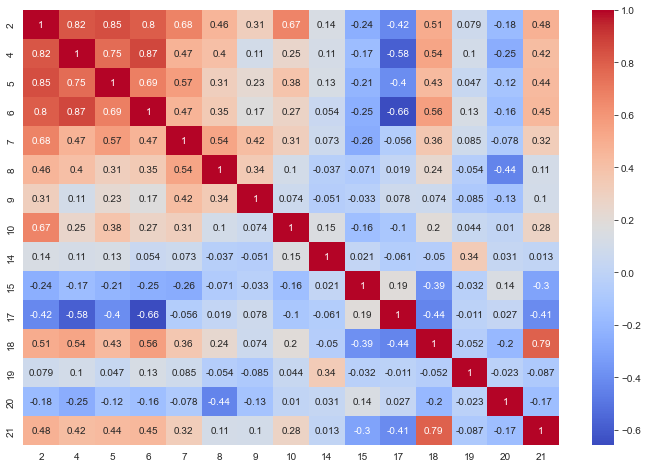

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.show()

In [13]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [17]:
# Initialisiere den PCA
pca = PCA(n_components=2)

mat = df2.values

# Trainiere den PCA auf den Daten
pca.fit(mat)

PCA(n_components=2)

In [18]:
pca_mat = pca.transform(mat)

In [19]:
pca_mat

array([[-1.12165994,  0.31472726],
       [-1.01501831,  0.11885275],
       [-1.06286914,  0.27574681],
       [-1.11787805,  0.35222447],
       [-1.03153619,  0.34802005],
       [-1.05183478,  0.33511486],
       [-0.97115585,  0.23591267],
       [-1.0525561 ,  0.28150849],
       [-0.97330315,  0.21150304],
       [-1.02685167,  0.42112827],
       [-0.66453939, -0.1422919 ],
       [-0.64082768, -0.52435541],
       [-0.88291857,  0.16242334],
       [-0.42354672, -0.37044948],
       [-0.82382199,  0.22205865],
       [-0.44356432, -0.39545631],
       [-0.97139392,  0.52350143],
       [-0.84040533,  0.11008894],
       [-0.79909152, -0.03877538],
       [-0.79265989,  0.54990169],
       [-0.78701095,  0.21155334],
       [-0.56044346, -0.00164854],
       [-0.35498929, -0.46213093],
       [-0.91971158,  0.61272885],
       [-0.4575461 , -0.4710892 ],
       [-0.7942521 ,  0.04793304],
       [-0.46450299, -0.37450926],
       [-0.74157937,  0.61297222],
       [-0.6652587 ,

In [20]:
# Initialisiere K-Means mit 3 Clustern
kmeans = KMeans(n_clusters=3)

# Trainiere K-Means auf den transformierten Daten
kmeans.fit(pca_mat)

# Erhalte die Cluster-Labels für jede Zeile in den transformierten Daten
labels = kmeans.labels_

# Erhalte die Cluster-Zentren
centers = kmeans.cluster_centers_

# Anzeigen der Ergebnisse
print("Cluster-Labels:")
print(labels)
print("Cluster-Zentren:")
print(centers)

Cluster-Labels:
[2 2 2 2 2 2 2 2 2 2 2 1 2 1 2 1 2 2 2 2 2 2 1 2 1 2 1 2 2 1 2 2 1 1 2 2 2
 2 2 1 1 1 1 1 2 2 2 1 2 1 1 1 1 1 2 1 1 1 2 1 1 1 1 1 1 2 1 0 2 1 2 2 1 1
 1 1 0 1 1 0 1 0 1 0 1 1 1 1 1 0 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1 0 0 0 1 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0]
Cluster-Zentren:
[[ 0.56935801  0.16087587]
 [-0.05213286 -0.28679921]
 [-0.70597131  0.20182451]]


In [24]:
ids = list()

for index, label in enumerate(labels):
    country_id = df2.index[index]

    if label == 2:        
        ids.append(country_id)

print(ids)

[216, 103, 61, 167, 41, 76, 157, 215, 159, 14, 110, 15, 236, 131, 108, 22, 234, 235, 168, 201, 84, 181, 77, 60, 238, 196, 210, 138, 218, 121, 203, 113, 120, 18, 204, 21, 59, 229, 101, 70]


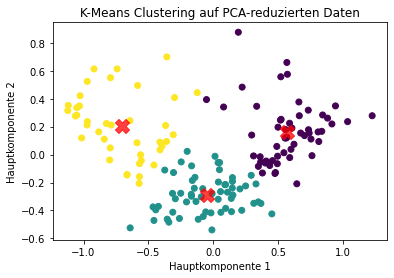

In [21]:
import matplotlib.pyplot as plt

# Plotte die transformierten Datenpunkte
plt.scatter(pca_mat[:, 0], pca_mat[:, 1], c=labels, cmap='viridis')

# Plotte die Cluster-Zentren

plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.75, marker='X')
plt.title('K-Means Clustering auf PCA-reduzierten Daten')
plt.xlabel('Hauptkomponente 1')
plt.ylabel('Hauptkomponente 2')
plt.show()